In [1]:
import subprocess, sys, warnings, os, math, random, json, time, gc, ctypes

def pip(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

print("Installing...")
for p in ["rdkit", "kagglehub", "scipy", "tqdm", "matplotlib", "pandas", "numpy", "scikit-learn"]:
    pip(p)
print("Done.")

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import defaultdict, Counter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from rdkit.Chem.rdchem import BondType
RDLogger.DisableLog("rdApp.*")

# glibc handle — used for malloc_trim(0) to return freed pages to OS
try:
    _libc = ctypes.CDLL("libc.so.6")
    print("libc.so.6 loaded (malloc_trim enabled)")
except OSError:
    _libc = None
    print("libc not found — malloc_trim disabled (RAM may grow slightly)")

def malloc_trim():
    """Force glibc to return freed pages to OS."""
    gc.collect()
    if _libc is not None:
        _libc.malloc_trim(0)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Speed-oriented settings (reproducibility is not the main target here)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    except Exception:
        pass

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

GRID        = 64
N_CH        = 7
IN_CH       = 14
ATOM_SIGMA  = 1.8
BOND_SIGMA  = 1.2
PADDING     = 0.12
BATCH       = 128 if torch.cuda.is_available() else 64
LR          = 5e-4
MAX_EPOCHS  = 60
ES_PATIENCE = 12
THRESHOLD   = 0.45
W_MASK      = 0.60
W_RECON     = 0.20
W_DELTA     = 0.15
W_SPARSE    = 0.05

for d in ["results/figures", "results/models", "data"]:
    os.makedirs(d, exist_ok=True)

print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
    print(f"GPUs   : {torch.cuda.device_count()}")
print(f"Grid   : {GRID}x{GRID}   IN_CH={IN_CH}   BATCH={BATCH}")
print("Config OK.")


Installing...
Done.
libc.so.6 loaded (malloc_trim enabled)
Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB
GPUs   : 1
Grid   : 64x64   IN_CH=14   BATCH=128
Config OK.


In [2]:
# ================================================================
#  SECTION 1 — MCR TENSOR ENCODER
#
#  Channels (committed — do not change):
#    CH0: atomic number / 118      (element identity)
#    CH1: bond order               (PRIMARY reaction signal)
#    CH2: formal charge [0,1]      (ion formation)
#    CH3: aromaticity binary       (ring reactivity)
#    CH4: ring membership binary   (ring context)
#    CH5: total H count / 8        (H environment)
#    CH6: RC hint — ALWAYS ZERO in model input (rc_atoms=None)
# ================================================================

from functools import lru_cache

_BOND_VAL = {
    BondType.SINGLE  : 0.333,
    BondType.AROMATIC: 0.500,
    BondType.DOUBLE  : 0.667,
    BondType.TRIPLE  : 1.000,
}
def _bv(bond): return _BOND_VAL.get(bond.GetBondType(), 0.333)
def _mbv(atom): return max((_bv(b) for b in atom.GetBonds()), default=0.0)

@lru_cache(maxsize=8)
def _grid_coords(G):
    col = np.arange(G, dtype=np.float32).reshape(1,1,G)
    row = np.arange(G, dtype=np.float32).reshape(1,G,1)
    return col, row

def _gauss_batch(canvas, cx_arr, cy_arr, sigma, val_arr):
    """Vectorized: draw N Gaussians in one numpy op."""
    if len(cx_arr) == 0:
        return
    G = canvas.shape[0]
    col, row = _grid_coords(G)
    cx  = np.asarray(cx_arr, dtype=np.float32).reshape(-1,1,1)
    cy  = np.asarray(cy_arr, dtype=np.float32).reshape(-1,1,1)
    val = np.asarray(val_arr, dtype=np.float32).reshape(-1,1,1)
    canvas += (val * np.exp(-((col-cx)**2 + (row-cy)**2) / (2 * sigma**2))).sum(0)

def smiles_to_tensor(smi, grid=GRID, rc_atoms=None, padding=PADDING):
    """
    SMILES -> [7, grid, grid] float32 or None.
    rc_atoms=None keeps CH6 zero — no RC hint leakage into model input.
    """
    mol = Chem.MolFromSmiles(str(smi))
    if mol is None:
        return None
    mol = Chem.AddHs(mol, addCoords=False)
    try:
        AllChem.Compute2DCoords(mol)
    except Exception:
        return None
    mol = Chem.RemoveHs(mol)
    conf = mol.GetConformer()
    n = mol.GetNumAtoms()
    if n == 0:
        return None

    xs = np.array([conf.GetAtomPosition(i).x for i in range(n)], dtype=np.float32)
    ys = np.array([conf.GetAtomPosition(i).y for i in range(n)], dtype=np.float32)
    span  = max(xs.max() - xs.min(), ys.max() - ys.min(), 1e-6)
    inner = grid * (1 - 2 * padding)
    gx    = grid * padding + (xs - xs.min()) / span * inner
    gy    = grid * padding + (ys - ys.min()) / span * inner
    gx   += (grid - (gx.max() + gx.min())) / 2
    gy   += (grid - (gy.max() + gy.min())) / 2

    T = np.zeros((N_CH, grid, grid), dtype=np.float32)
    atoms = list(mol.GetAtoms())
    rc = set(rc_atoms) if rc_atoms else set()

    an  = np.array([a.GetAtomicNum() / 118.0                           for a in atoms], dtype=np.float32)
    bo  = np.array([_mbv(a)                                            for a in atoms], dtype=np.float32)
    chg = np.array([float(np.clip((a.GetFormalCharge() + 4) / 8.0, 0, 1)) for a in atoms], dtype=np.float32)
    ar  = np.array([1.0 if a.GetIsAromatic() else 0.0                  for a in atoms], dtype=np.float32)
    ri  = np.array([1.0 if a.IsInRing() else 0.0                       for a in atoms], dtype=np.float32)
    hc  = np.array([a.GetTotalNumHs() / 8.0                            for a in atoms], dtype=np.float32)

    s = ATOM_SIGMA
    _gauss_batch(T[0], gx, gy, s,     an)
    _gauss_batch(T[1], gx, gy, s*0.6,  bo)
    _gauss_batch(T[2], gx, gy, s,     chg)
    _gauss_batch(T[3], gx, gy, s,     ar)
    _gauss_batch(T[4], gx, gy, s,     ri)
    _gauss_batch(T[5], gx, gy, s,     hc)

    if rc:
        rc_list = [i for i in range(n) if i in rc]
        if rc_list:
            ri_arr = np.array(rc_list, dtype=int)
            _gauss_batch(T[6], gx[ri_arr], gy[ri_arr], s*1.2,
                         np.ones(len(ri_arr), dtype=np.float32))

    bx, by, bv = [], [], []
    for bond in mol.GetBonds():
        i0, i1 = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        dx, dy = gx[i1] - gx[i0], gy[i1] - gy[i0]
        L = math.hypot(dx, dy)
        if L < 1e-3:
            continue
        nb2 = max(int(L * 2), 4)
        bvv = _bv(bond) / (nb2 + 1)
        ts = np.linspace(0, 1, nb2 + 1, dtype=np.float32)
        bx.append(gx[i0] + ts * dx)
        by.append(gy[i0] + ts * dy)
        bv.append(np.full(nb2 + 1, bvv, dtype=np.float32))
    if bx:
        _gauss_batch(T[1], np.concatenate(bx), np.concatenate(by),
                     BOND_SIGMA, np.concatenate(bv))

    np.clip(T, 0, 1, out=T)
    return T

def reaction_center_map_numbers(smi_r, smi_p):
    """Return RC atom MAP NUMBERS (not indices) — safe across fragments."""
    mr = Chem.MolFromSmiles(str(smi_r))
    mp = Chem.MolFromSmiles(str(smi_p))
    if mr is None or mp is None:
        return set()

    def bfp(mol):
        fp = {}
        for b in mol.GetBonds():
            a = b.GetBeginAtom().GetAtomMapNum()
            bb = b.GetEndAtom().GetAtomMapNum()
            if a > 0 and bb > 0:
                fp[(min(a, bb), max(a, bb))] = b.GetBondType()
        return fp

    fp_r, fp_p = bfp(mr), bfp(mp)
    rc = set()
    for k in set(fp_r) | set(fp_p):
        if fp_r.get(k) != fp_p.get(k):
            rc.update(k)
    rc.update({a.GetAtomMapNum() for a in mr.GetAtoms() if a.GetAtomMapNum()} -
              {a.GetAtomMapNum() for a in mp.GetAtoms() if a.GetAtomMapNum()})
    return rc

def reaction_center_from_atom_maps(smi_r, smi_p):
    mol = Chem.MolFromSmiles(str(smi_r))
    if mol is None:
        return set()
    rc = reaction_center_map_numbers(smi_r, smi_p)
    return {a.GetIdx() for a in mol.GetAtoms() if a.GetAtomMapNum() in rc}

def compute_rc_mask(smi_r, smi_p, grid=GRID):
    mol = Chem.MolFromSmiles(str(smi_r))
    if mol is None:
        return None
    rc_idx = reaction_center_from_atom_maps(smi_r, smi_p)
    if not rc_idx:
        return None
    T = smiles_to_tensor(smi_r, grid=grid, rc_atoms=rc_idx)
    if T is None:
        return None
    mask = (T[6] > 0.1).astype(np.uint8)
    return mask if mask.sum() >= 1 else None

# Smoke test
print("Smoke test...")
for name, smi in [
    ("Aspirin", "CC(=O)Oc1ccccc1C(=O)O"),
    ("Caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C"),
    ("Benzene", "c1ccccc1"),
    ("Ethanol", "CCO"),
]:
    T = smiles_to_tensor(smi)
    ok = T is not None and T.shape == (N_CH, GRID, GRID) and 0 <= T.min() and T.max() <= 1
    print(f"  {name:<12} shape={T.shape}  CH0={T[0].max():.2f}  CH1={T[1].max():.2f}  {'OK' if ok else 'FAIL'}")
print("Encoder OK.")


Smoke test...
  Aspirin      shape=(7, 64, 64)  CH0=0.07  CH1=0.78  OK
  Caffeine     shape=(7, 64, 64)  CH0=0.07  CH1=0.91  OK
  Benzene      shape=(7, 64, 64)  CH0=0.05  CH1=0.57  OK
  Ethanol      shape=(7, 64, 64)  CH0=0.07  CH1=0.38  OK
Encoder OK.


In [3]:
import kagglehub
print("Downloading dataset...")
DATASET_PATH = kagglehub.dataset_download("anonytemp/uspto-50k-with-reaction-classes")
print(f"Path: {DATASET_PATH}  Files: {os.listdir(DATASET_PATH)}")

def _detect_fmt(df):
    cols = {c.lower().strip(): c for c in df.columns}
    cls_col = None
    for kw in ["reaction_class", "class", "rxn_class", "type", "category"]:
        if kw in cols:
            cls_col = cols[kw]
            break
    if cls_col is None:
        for c in df.columns:
            try:
                if df[c].dropna().astype(str).str.match(r"^\d+$").mean() > 0.8:
                    cls_col = c
                    break
            except Exception:
                pass
    for kw in ["rxn_smiles", "reaction_smiles", "rxn", "smiles", "mapped"]:
        if kw in cols:
            s = str(df[cols[kw]].dropna().iloc[0])
            if ">>" in s:
                return None, None, cls_col, cols[kw], "rxn"
    r_col = p_col = None
    for kw in ["reactants_mol", "reactants", "reactant", "react", "source"]:
        if kw in cols and r_col is None:
            r_col = cols[kw]
    for kw in ["products_mol", "products", "product", "prod", "target"]:
        if kw in cols and p_col is None:
            p_col = cols[kw]
    if r_col and p_col:
        return r_col, p_col, cls_col, None, "two"
    for oc in df.columns:
        try:
            if ">>" in str(df[oc].dropna().iloc[0]):
                return None, None, cls_col, oc, "rxn"
        except Exception:
            pass
    cl = list(df.columns)
    return cl[-2], cl[-1], cls_col, None, "two"

def load_dataset(path):
    csvs = sorted([f for f in os.listdir(path) if f.endswith(".csv")])
    print(f"Files: {csvs}")
    splits = {}

    for fname in csvs:
        df = pd.read_csv(os.path.join(path, fname))
        print(f"\n{fname}: {df.shape[0]} rows  cols={list(df.columns)}")
        r_col, p_col, cls_col, rxn_col, fmt = _detect_fmt(df)
        print(f"  fmt={fmt}  r={r_col}  p={p_col}  cls={cls_col}")

        records = []
        if fmt == "rxn":
            rxns = df[rxn_col].astype(str).tolist()
            cls_vals = df[cls_col].astype(str).tolist() if cls_col else ["Unknown"] * len(rxns)
            for rxn, c in zip(rxns, cls_vals):
                rxn = rxn.strip()
                if ">>" not in rxn:
                    continue
                reactants, product = rxn.split(">>", 1)
                reactants = reactants.strip()
                product = product.split(".")[0].strip()
                if not reactants or not product or len(product) < 2 or reactants == product:
                    continue
                records.append({
                    "reactants": reactants,
                    "product": product,
                    "reaction_class": c,
                    "rxn_smiles": f"{reactants}>>{product}",
                })
        else:
            rs = df[r_col].astype(str).tolist()
            ps = df[p_col].astype(str).tolist()
            cls_vals = df[cls_col].astype(str).tolist() if cls_col else ["Unknown"] * len(rs)
            for r, p, c in zip(rs, ps, cls_vals):
                r = r.strip()
                p = p.strip().split(".")[0].strip()
                if not r or not p or len(p) < 2 or r == p:
                    continue
                records.append({
                    "reactants": r,
                    "product": p,
                    "reaction_class": c,
                    "rxn_smiles": f"{r}>>{p}",
                })

        print(f"  Parsed: {len(records)}")
        nl = fname.lower()
        sp = (
            "train" if "train" in nl else
            "val" if "val" in nl or "valid" in nl else
            "test" if "test" in nl else
            "_all_"
        )
        splits.setdefault(sp, []).extend(records)

    if "_all_" in splits:
        all_r = splits.pop("_all_")
        random.shuffle(all_r)
        n = len(all_r)
        splits["train"] = all_r[:int(0.80*n)]
        splits["val"]   = all_r[int(0.80*n):int(0.90*n)]
        splits["test"]  = all_r[int(0.90*n):]
        print("80/10/10 split applied.")
    return splits

splits     = load_dataset(DATASET_PATH)
TRAIN_RECS = splits.get("train", [])
VAL_RECS   = splits.get("val", [])
TEST_RECS  = splits.get("test", [])
print(f"\nTrain={len(TRAIN_RECS)}  Val={len(VAL_RECS)}  Test={len(TEST_RECS)}")


100%|██████████| 3.82M/3.82M [00:00<00:00, 209MB/s]

Extracting files...
Path: /root/.cache/kagglehub/datasets/anonytemp/uspto-50k-with-reaction-classes/versions/1  Files: ['rxn_test.csv', 'rxnclass10_test.csv', 'rxn_val.csv', 'rxn_train.csv']
Files: ['rxn_test.csv', 'rxn_train.csv', 'rxn_val.csv', 'rxnclass10_test.csv']

rxn_test.csv: 5007 rows  cols=['id', 'class', 'reactants>reagents>production']
  fmt=rxn  r=None  p=None  cls=class
  Parsed: 5007



rxn_train.csv: 40008 rows  cols=['id', 'class', 'reactants>reagents>production']
  fmt=rxn  r=None  p=None  cls=class
  Parsed: 40008

rxn_val.csv: 5001 rows  cols=['id', 'class', 'reactants>reagents>production']
  fmt=rxn  r=None  p=None  cls=class
  Parsed: 5001

rxnclass10_test.csv: 23 rows  cols=['id', 'class', 'reactants>reagents>production']
  fmt=rxn  r=None  p=None  cls=class
  Parsed: 23

Train=40008  Val=5001  Test=5030


In [4]:
# ================================================================
#  SECTION 3 — DATASET  (memory + throughput optimized)
#
#  Main fixes:
#    1. Product tensor is cached once per sample (no per-epoch RDKit call)
#    2. Dataset returns torch.from_numpy(...) to avoid extra copies
#    3. Product tensor is stored as uint8 (0..255) to reduce RAM
#    4. CSV parsing avoids slow iterrows()
# ================================================================

def _to_u8(x):
    return np.clip(np.rint(x * 255.0), 0, 255).astype(np.uint8)

def _from_u8(x):
    return x.astype(np.float32) / 255.0

def build_sample(record):
    """
    Store compact tensors.
    CH6 is always zero in model input (rc_atoms=None).
    """
    reactants = record["reactants"]
    product   = record["product"]

    parts = [p.strip() for p in reactants.split(".") if len(p.strip()) > 1]
    if not parts:
        return None
    if len(parts) == 1:
        smi_A = smi_B = parts[0]
    else:
        mid = max(1, len(parts) // 2)
        smi_A = ".".join(parts[:mid])
        smi_B = ".".join(parts[mid:])

    # Core tensors
    T_A = smiles_to_tensor(smi_A, rc_atoms=None)
    T_B = smiles_to_tensor(smi_B, rc_atoms=None)
    T_P = smiles_to_tensor(product, rc_atoms=None)
    if T_A is None or T_B is None or T_P is None:
        return None

    # Ground-truth mask
    rc_idx = reaction_center_from_atom_maps(reactants, product)
    if rc_idx:
        T_mask = smiles_to_tensor(reactants, rc_atoms=rc_idx)
        if T_mask is None:
            return None
        mask = (T_mask[6] > 0.1).astype(np.uint8)
    else:
        diff = np.abs(T_P[1] - T_A[1])
        mask = (diff > 0.05).astype(np.uint8)

    if mask.sum() < 1:
        return None

    # Deltas
    d_at = np.clip(T_P[0] - T_A[0], -1, 1).astype(np.float16, copy=False)
    d_bo = np.clip(T_P[1] - T_A[1], -1, 1).astype(np.float16, copy=False)
    d_ch = np.clip(T_P[2] - T_A[2], -1, 1).astype(np.float16, copy=False)

    X = np.ascontiguousarray(np.concatenate([T_A, T_B], axis=0).astype(np.float16, copy=False))
    T_prod_u8 = np.ascontiguousarray(_to_u8(T_P))

    del T_A, T_B, T_P

    return {
        "X"             : X,          # float16 [14,64,64]
        "mask"          : mask,       # uint8   [64,64]
        "T_prod_u8"     : T_prod_u8,  # uint8   [7,64,64]
        "delta_atoms"   : d_at,       # float16 [64,64]
        "delta_bonds"   : d_bo,       # float16 [64,64]
        "delta_charge"  : d_ch,       # float16 [64,64]
        "product_smi"   : product,
        "reaction_class": record["reaction_class"],
        "reactants"    : record["reactants"],
        "product"      : record["product"],
    }

class MCRDataset(Dataset):
    def __init__(self, records, desc="Building"):
        self.samples = []
        skipped = 0
        print(f"  [{desc}] {len(records)} records")
        sys.stdout.flush()
        for i, rec in enumerate(tqdm(records, desc=f"  {desc}", leave=True)):
            s = build_sample(rec)
            if s is not None:
                self.samples.append(s)
            else:
                skipped += 1
            if (i + 1) % 2000 == 0:
                malloc_trim()
        malloc_trim()
        print(f"  {desc}: {len(self.samples)} samples ({skipped} skipped)")
        if self.samples:
            kb = (
                self.samples[0]["X"].nbytes +
                self.samples[0]["mask"].nbytes +
                self.samples[0]["T_prod_u8"].nbytes +
                self.samples[0]["delta_atoms"].nbytes * 3
            ) / 1024
            print(f"  RAM: ~{len(self.samples) * kb / 1e6:.1f} GB (X float16 + T_prod uint8)")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        # torch.from_numpy avoids an extra copy
        return (
            torch.from_numpy(s["X"]),
            torch.from_numpy(s["mask"]).unsqueeze(0),
            torch.from_numpy(s["T_prod_u8"]),
            torch.from_numpy(s["delta_atoms"]).unsqueeze(0),
            torch.from_numpy(s["delta_bonds"]).unsqueeze(0),
            torch.from_numpy(s["delta_charge"]).unsqueeze(0),
            s["reaction_class"],
        )

def _loader_kwargs(train=True):
    n_workers = 2 if torch.cuda.is_available() else 0
    kwargs = dict(
        batch_size=BATCH,
        shuffle=train,
        num_workers=n_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(n_workers > 0),
    )
    if n_workers > 0:
        kwargs["prefetch_factor"] = 2
    return kwargs

# Build TRAIN and VAL only — DS_TEST deferred to Section 8/9
print("Building datasets (cached T_prod, test=deferred)...")
DS_TRAIN = MCRDataset(TRAIN_RECS, "Train"); malloc_trim()
DS_VAL   = MCRDataset(VAL_RECS,   "Val");   malloc_trim()
DS_TEST  = None
DL_TEST  = None

DL_TRAIN = DataLoader(DS_TRAIN, **_loader_kwargs(train=True))
DL_VAL   = DataLoader(DS_VAL,   **_loader_kwargs(train=False))

print(f"\nDataLoaders ready.")
print(f"  Train : {len(DS_TRAIN):>6} samples  {len(DL_TRAIN)} batches")
print(f"  Val   : {len(DS_VAL):>6} samples  {len(DL_VAL)} batches")
print(f"  Test  : deferred to Section 8")
sps = [DS_VAL.samples[i]["mask"].mean() for i in range(min(200, len(DS_VAL)))]
print(f"\nSparsity (val): mean={np.mean(sps):.2%}  median={np.median(sps):.2%}  <5%={np.mean([s < 0.05 for s in sps]):.1%}")


Building datasets (cached T_prod, test=deferred)...
  [Train] 40008 records


  Train:   0%|          | 0/40008 [00:00<?, ?it/s]

  Train: 40008 samples (0 skipped)
  RAM: ~6.7 GB (X float16 + T_prod uint8)
  [Val] 5001 records


  Val:   0%|          | 0/5001 [00:00<?, ?it/s]

  Val: 5001 samples (0 skipped)
  RAM: ~0.8 GB (X float16 + T_prod uint8)

DataLoaders ready.
  Train :  40008 samples  313 batches
  Val   :   5001 samples  40 batches
  Test  : deferred to Section 8

Sparsity (val): mean=3.71%  median=3.30%  <5%=96.0%


In [5]:
import torch, torch.nn as nn, os
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GRID, N_CH, IN_CH = 64, 7, 14
os.makedirs("results/models", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

class ConvBlock(nn.Module):
    """Conv-BN-ReLU -> Dropout2d -> Conv-BN-ReLU."""
    def __init__(self, in_c, out_c, drop=0.0):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )
        self.drop = nn.Dropout2d(drop) if drop > 0 else nn.Identity()
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.conv2(self.drop(self.conv1(x)))

class MCRNet64(nn.Module):
    def __init__(self, in_ch=IN_CH, drop=0.25):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.enc1 = ConvBlock(in_ch, 32,  drop=drop)
        self.enc2 = ConvBlock(32,    64,  drop=drop)
        self.enc3 = ConvBlock(64,   128,  drop=drop)
        self.enc4 = ConvBlock(128,  256,  drop=drop)
        self.bot  = ConvBlock(256,  512,  drop=drop)
        self.up4  = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = ConvBlock(512, 256, drop=drop)
        self.up3  = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128, drop=drop)
        self.up2  = nn.ConvTranspose2d(128, 64,  2, stride=2)
        self.dec2 = ConvBlock(128, 64,  drop=drop)
        self.up1  = nn.ConvTranspose2d(64,  32,  2, stride=2)
        self.dec1 = ConvBlock(64, 32, drop=0.0)
        self.mask_head = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Sigmoid())
        nn.init.constant_(self.mask_head[0].bias, -2.2)  # sigmoid(-2.2)≈0.10
        self.h_at = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())
        self.h_bo = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())
        self.h_ch = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bot(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        f  = self.dec1(torch.cat([self.up1(d2), e1], 1))

        mask = self.mask_head(f)
        da = self.h_at(f)
        db = self.h_bo(f)
        dc = self.h_ch(f)

        T_r = x[:, :N_CH]
        T_p = T_r.clone()
        T_p[:, 0:1] = torch.clamp(T_p[:, 0:1] + mask * da, 0, 1)
        T_p[:, 1:2] = torch.clamp(T_p[:, 1:2] + mask * db, 0, 1)
        T_p[:, 2:3] = torch.clamp(T_p[:, 2:3] + mask * dc, 0, 1)
        return mask, da, db, dc, T_p

MODEL = MCRNet64(in_ch=IN_CH).to(DEVICE)
if DEVICE.type == "cuda":
    MODEL = MODEL.to(memory_format=torch.channels_last)

n_p = sum(p.numel() for p in MODEL.parameters())
print(f"MCR-Net v5  |  Parameters: {n_p:,}")
_d = torch.zeros(2, IN_CH, GRID, GRID, device=DEVICE)
if DEVICE.type == "cuda":
    _d = _d.to(memory_format=torch.channels_last)
_m, _da, _db, _dc, _tp = MODEL(_d)
assert _m.shape == (2, 1, GRID, GRID) and _tp.shape == (2, N_CH, GRID, GRID)
print(f"Shapes: mask={tuple(_m.shape)}  T_product={tuple(_tp.shape)}")
del _d, _m, _da, _db, _dc, _tp
print("Architecture OK.")


MCR-Net v5  |  Parameters: 7,766,308
Shapes: mask=(2, 1, 64, 64)  T_product=(2, 7, 64, 64)
Architecture OK.


In [6]:
import torch, torch.nn.functional as F
THRESHOLD = 0.45
W_MASK    = 0.60
W_RECON   = 0.20
W_DELTA   = 0.15
W_SPARSE  = 0.05
ES_PATIENCE = 12

def focal_loss(pred, target, alpha=0.85, gamma=2.0):
    """
    AMP-safe focal loss.
    Uses log(pred) directly (not BCE function) so it works in float16.
    Casts to float32 first for numerical safety.
    """
    pred   = pred.float().clamp(1e-6, 1 - 1e-6)
    target = target.float()
    bce    = -(target * torch.log(pred) + (1 - target) * torch.log(1 - pred))
    pt     = torch.where(target > 0.5, pred, 1.0 - pred)
    return (alpha * (1.0 - pt).pow(gamma) * bce).mean()

def dice_loss(pred, target, smooth=1.0):
    pred, target = pred.float(), target.float()
    inter = (pred * target).sum()
    return 1.0 - (2.0 * inter + smooth) / (pred.sum() + target.sum() + smooth)

def masked_recon_loss(T_pred, T_true, mask):
    T_pred, T_true, mask = T_pred.float(), T_true.float(), mask.float()
    m = mask.expand_as(T_pred)
    return ((T_pred - T_true).pow(2) * m).sum() / m.sum().clamp(min=1.0)

def mcr_loss(mp, dap, dbp, dcp, Tpp, mt, dat, dbt, dct, Tpt, alpha=0.85):
    # All casts to float32 happen inside each function — safe with AMP
    L_m = (0.5 * focal_loss(mp, mt, alpha=alpha) + 0.5 * dice_loss(mp, mt))
    L_r = masked_recon_loss(Tpp, Tpt, mt)
    L_d = (
        F.mse_loss(dap.float(), dat.float()) +
        F.mse_loss(dbp.float(), dbt.float()) +
        F.mse_loss(dcp.float(), dct.float())
    ) / 3.0
    L_s = (dap.float().abs().mean() + dbp.float().abs().mean() + dcp.float().abs().mean()) / 3.0
    total = W_MASK * L_m + W_RECON * L_r + W_DELTA * L_d + W_SPARSE * L_s
    return total, {"mask": L_m.item(), "recon": L_r.item(), "delta": L_d.item(), "sparse": L_s.item()}

def compute_metrics(pm, tm, thr=THRESHOLD):
    pb = (pm > thr).float()
    tb = (tm > 0.5).float()
    TP = (pb * tb).sum().item()
    FP = (pb * (1 - tb)).sum().item()
    FN = ((1 - pb) * tb).sum().item()
    P = TP / (TP + FP + 1e-8)
    R = TP / (TP + FN + 1e-8)
    F1 = 2 * P * R / (P + R + 1e-8)
    IoU = TP / (TP + FP + FN + 1e-8)
    CR = ((pb * tb).view(pb.shape[0], -1).sum(1) > 0).float().mean().item()
    return dict(precision=P, recall=R, f1=F1, iou=IoU, center_recall=CR)

class EarlyStopping:
    def __init__(self, patience=ES_PATIENCE, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best = None
        self.best_state = None
        self.stop = False
    def step(self, score, model):
        if self.best is None or score > self.best + self.min_delta:
            self.best = score
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
    def load_best(self, model):
        if self.best_state:
            model.load_state_dict(self.best_state)

print("Loss functions and metrics defined.")
print(f"  Weights: mask={W_MASK} recon={W_RECON} delta={W_DELTA} sparse={W_SPARSE}")


Loss functions and metrics defined.
  Weights: mask=0.6 recon=0.2 delta=0.15 sparse=0.05


In [7]:
# ================================================================
#  SECTION 6 — TRAINING LOOP
#
#  Main fixes:
#    - cached product tensor so __getitem__ is lightweight
#    - channels_last on GPU for faster convolutions
#    - non_blocking=True + pinned memory
#    - optimizer zero_grad(set_to_none=True)
#    - fixed typo MODEL=MODE
#    - validation uses inference_mode and streaming metrics
# ================================================================

import sys, os, time
from collections import defaultdict
from torch.cuda.amp import autocast, GradScaler

for name in ["MODEL", "DL_TRAIN", "DL_VAL", "DS_TRAIN", "DS_VAL",
             "mcr_loss", "compute_metrics", "EarlyStopping", "malloc_trim"]:
    if name not in dir():
        raise RuntimeError(f"{name} not defined — run Sections 0-5 first.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LR = 5e-4
MAX_EPOCHS = 60
os.makedirs("results/models", exist_ok=True)

_raw_model = MODEL
if torch.cuda.device_count() > 1:
    print(f"Multi-GPU: {torch.cuda.device_count()} GPUs → DataParallel")
    MODEL = torch.nn.DataParallel(MODEL)

OPT = torch.optim.AdamW(_raw_model.parameters(), lr=LR, weight_decay=1e-4)
SCHED = torch.optim.lr_scheduler.OneCycleLR(
    OPT,
    max_lr=LR,
    epochs=MAX_EPOCHS,
    steps_per_epoch=len(DL_TRAIN),
    pct_start=0.3,
    anneal_strategy="cos",
    div_factor=25,
    final_div_factor=1e4,
)
ES = EarlyStopping(patience=ES_PATIENCE)
HIST = defaultdict(list)
SCALER = GradScaler(enabled=(DEVICE.type == "cuda"))

print(f"Training MCR-Net  Device={DEVICE}  GPUs={torch.cuda.device_count()}")
print(f"  Epochs={MAX_EPOCHS}  Batch={BATCH}  LR={LR}  AMP=ON")
print(f"  Train={len(DS_TRAIN)}  Val={len(DS_VAL)}")
print(f"  RAM: cached product tensor + pinned transfers")
sys.stdout.flush()

t_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    alpha = min(0.85, 0.50 + 0.35 * epoch / 20)

    # ── Train ────────────────────────────────────────────────
    MODEL.train()
    t_loss = 0.0
    t_parts = defaultdict(float)

    for X, mt, Tpt, dat, dbt, dct, _ in DL_TRAIN:
        X   = X.to(DEVICE, non_blocking=True)
        mt  = mt.to(DEVICE, non_blocking=True).float()
        Tpt = Tpt.to(DEVICE, non_blocking=True).float().div_(255.0)
        dat = dat.to(DEVICE, non_blocking=True).float()
        dbt = dbt.to(DEVICE, non_blocking=True).float()
        dct = dct.to(DEVICE, non_blocking=True).float()

        if DEVICE.type == "cuda":
            X = X.contiguous(memory_format=torch.channels_last)

        OPT.zero_grad(set_to_none=True)

        with autocast(enabled=(DEVICE.type == "cuda")):
            mp, dap, dbp, dcp, Tpp = MODEL(X)

        loss, parts = mcr_loss(mp, dap, dbp, dcp, Tpp, mt, dat, dbt, dct, Tpt, alpha=alpha)

        SCALER.scale(loss).backward()
        SCALER.unscale_(OPT)
        torch.nn.utils.clip_grad_norm_(_raw_model.parameters(), 1.0)
        SCALER.step(OPT)
        SCALER.update()
        SCHED.step()

        t_loss += loss.item()
        for k, v in parts.items():
            t_parts[k] += v

    # ── Validate ─────────────────────────────────────────────
    MODEL.eval()
    v_loss = 0.0
    tp = fp = fn = cr = n = 0
    with torch.inference_mode():
        for X, mt, Tpt, dat, dbt, dct, _ in DL_VAL:
            X   = X.to(DEVICE, non_blocking=True)
            mt  = mt.to(DEVICE, non_blocking=True).float()
            Tpt = Tpt.to(DEVICE, non_blocking=True).float().div_(255.0)
            dat = dat.to(DEVICE, non_blocking=True).float()
            dbt = dbt.to(DEVICE, non_blocking=True).float()
            dct = dct.to(DEVICE, non_blocking=True).float()

            if DEVICE.type == "cuda":
                X = X.contiguous(memory_format=torch.channels_last)

            with autocast(enabled=(DEVICE.type == "cuda")):
                mp, dap, dbp, dcp, Tpp = MODEL(X)
            loss, _ = mcr_loss(mp, dap, dbp, dcp, Tpp, mt, dat, dbt, dct, Tpt, alpha=alpha)
            v_loss += loss.item()

            pm = mp.detach().float().cpu()
            tm = mt.detach().cpu()
            pb = pm > THRESHOLD
            tb = tm > 0.5
            tp += (pb & tb).sum().item()
            fp += (pb & (~tb)).sum().item()
            fn += ((~pb) & tb).sum().item()
            cr += ((pb & tb).view(pb.shape[0], -1).sum(1) > 0).sum().item()
            n  += pm.shape[0]

    avg_t = t_loss / len(DL_TRAIN)
    avg_v = v_loss / len(DL_VAL)
    lr_now = OPT.param_groups[0]["lr"]
    mm = dict(
        precision=tp / (tp + fp + 1e-8),
        recall=tp / (tp + fn + 1e-8),
        f1=(2 * (tp / (tp + fp + 1e-8)) * (tp / (tp + fn + 1e-8)) / ((tp / (tp + fp + 1e-8)) + (tp / (tp + fn + 1e-8)) + 1e-8)),
        iou=tp / (tp + fp + fn + 1e-8),
        center_recall=cr / max(n, 1),
    )

    malloc_trim()

    HIST["train_loss"].append(avg_t)
    HIST["val_loss"].append(avg_v)
    for k, v in mm.items():
        HIST[k].append(v)
    for k, v in t_parts.items():
        HIST[f"l_{k}"].append(v / len(DL_TRAIN))

    ES.step(mm["f1"], _raw_model)

    if epoch % 5 == 0 or epoch == 1:
        elapsed = (time.time() - t_start) / 60
        print(f"Ep {epoch:3d} | loss {avg_t:.4f}/{avg_v:.4f} | "
              f"P={mm['precision']:.3f} R={mm['recall']:.3f} "
              f"F1={mm['f1']:.3f} IoU={mm['iou']:.3f} "
              f"CR={mm['center_recall']:.3f} | "
              f"lr={lr_now:.1e} a={alpha:.2f} t={elapsed:.0f}m")
        sys.stdout.flush()

    if epoch % 10 == 0:
        ckpt = f"results/models/ckpt_ep{epoch:03d}.pt"
        torch.save(
            {"epoch": epoch, "model": _raw_model.state_dict(),
             "opt": OPT.state_dict(), "sched": SCHED.state_dict(),
             "scaler": SCALER.state_dict(), "hist": dict(HIST)},
            ckpt
        )
        print(f"  Checkpoint: {ckpt}")

    if ES.stop:
        print(f"[Early stop] epoch {epoch}")
        break

ES.load_best(_raw_model)
torch.save(_raw_model.state_dict(), "results/models/mcr_net_final.pt")
print(f"\nBest val F1 : {ES.best:.4f}")
print(f"Model saved : results/models/mcr_net_final.pt")
print(f"Total time  : {(time.time() - t_start)/3600:.2f} hours")


Training MCR-Net  Device=cuda  GPUs=1
  Epochs=60  Batch=128  LR=0.0005  AMP=ON
  Train=40008  Val=5001
  RAM: cached product tensor + pinned transfers
Ep   1 | loss 0.2660/0.2316 | P=0.565 R=0.527 F1=0.545 IoU=0.375 CR=0.285 | lr=2.4e-05 a=0.52 t=1m
Ep   5 | loss 0.2066/0.2006 | P=0.588 R=0.521 F1=0.552 IoU=0.382 CR=0.324 | lr=1.1e-04 a=0.59 t=2m
Ep  10 | loss 0.1715/0.1669 | P=0.612 R=0.623 F1=0.617 IoU=0.447 CR=0.930 | lr=3.0e-04 a=0.68 t=4m
  Checkpoint: results/models/ckpt_ep010.pt
Ep  15 | loss 0.1620/0.1602 | P=0.621 R=0.657 F1=0.639 IoU=0.469 CR=0.957 | lr=4.7e-04 a=0.76 t=6m
Ep  20 | loss 0.1539/0.1567 | P=0.622 R=0.690 F1=0.654 IoU=0.486 CR=0.962 | lr=5.0e-04 a=0.85 t=8m
  Checkpoint: results/models/ckpt_ep020.pt
Ep  25 | loss 0.1395/0.1462 | P=0.633 R=0.730 F1=0.678 IoU=0.513 CR=0.977 | lr=4.7e-04 a=0.85 t=11m
Ep  30 | loss 0.1245/0.1427 | P=0.640 R=0.744 F1=0.688 IoU=0.525 CR=0.977 | lr=4.1e-04 a=0.85 t=13m
  Checkpoint: results/models/ckpt_ep030.pt
Ep  35 | loss 0.1127/0.1

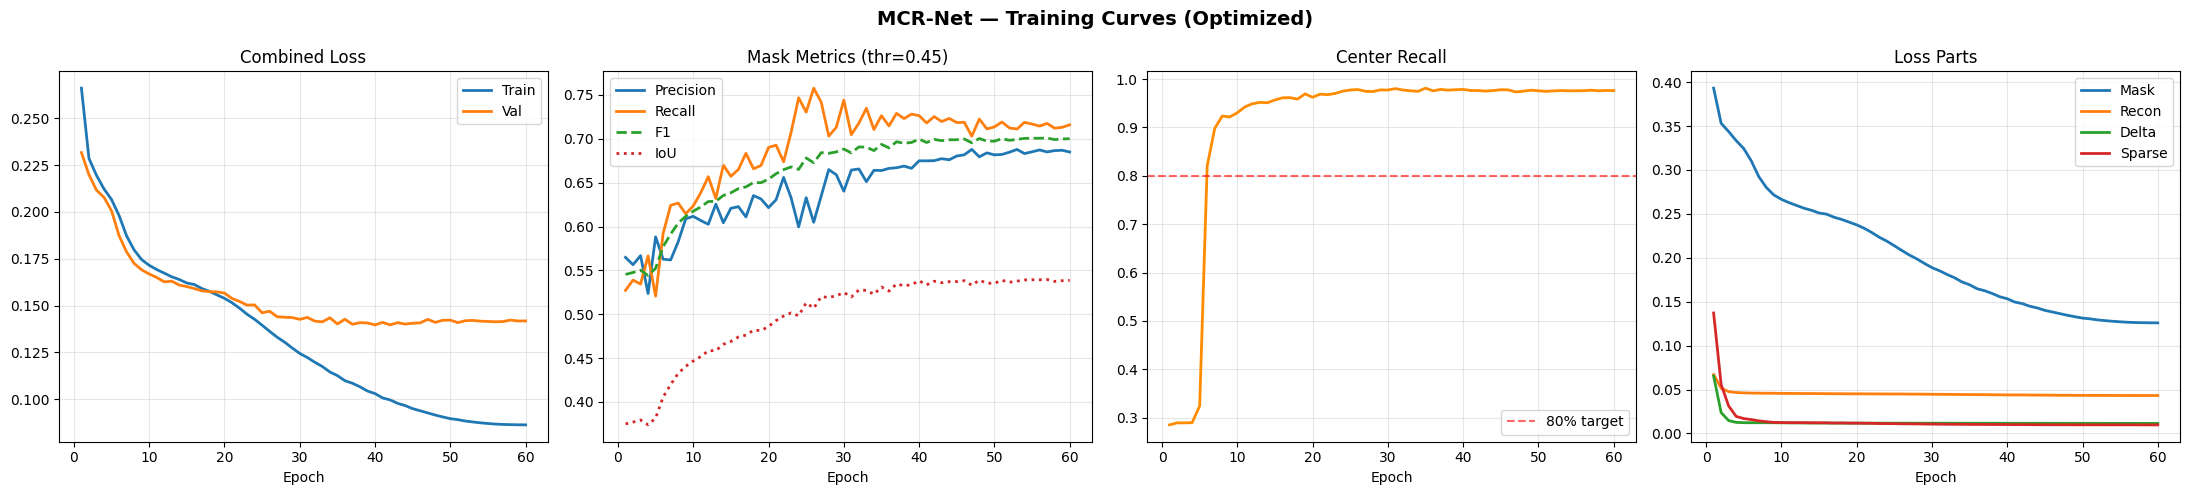

Saved: results/figures/training_curves.png


In [8]:
import os, matplotlib.pyplot as plt
from collections import defaultdict
THRESHOLD = 0.45
HIST = HIST if "HIST" in dir() else defaultdict(list)

if not HIST.get("train_loss"):
    print("No history — run Section 6 first.")
else:
    eps = range(1, len(HIST["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle("MCR-Net — Training Curves (Optimized)", fontsize=14, fontweight="bold")

    axes[0].plot(eps, HIST["train_loss"], label="Train", lw=2)
    axes[0].plot(eps, HIST["val_loss"],   label="Val",   lw=2)
    axes[0].set_title("Combined Loss")
    axes[0].legend()
    axes[0].set_xlabel("Epoch")
    axes[0].grid(alpha=0.3)

    axes[1].plot(eps, HIST["precision"], label="Precision", lw=2)
    axes[1].plot(eps, HIST["recall"],    label="Recall",    lw=2)
    axes[1].plot(eps, HIST["f1"],        label="F1",        lw=2, ls="--")
    axes[1].plot(eps, HIST["iou"],       label="IoU",       lw=2, ls=":")
    axes[1].set_title(f"Mask Metrics (thr={THRESHOLD})")
    axes[1].legend()
    axes[1].set_xlabel("Epoch")
    axes[1].grid(alpha=0.3)

    axes[2].plot(eps, HIST["center_recall"], color="darkorange", lw=2)
    axes[2].axhline(0.80, color="red", ls="--", alpha=0.6, label="80% target")
    axes[2].set_title("Center Recall")
    axes[2].legend()
    axes[2].set_xlabel("Epoch")
    axes[2].grid(alpha=0.3)

    axes[3].plot(eps, HIST["l_mask"],   label="Mask",   lw=2)
    axes[3].plot(eps, HIST["l_recon"],  label="Recon",  lw=2)
    axes[3].plot(eps, HIST["l_delta"],  label="Delta",  lw=2)
    axes[3].plot(eps, HIST["l_sparse"], label="Sparse", lw=2)
    axes[3].set_title("Loss Parts")
    axes[3].legend()
    axes[3].set_xlabel("Epoch")
    axes[3].grid(alpha=0.3)

    plt.tight_layout()
    os.makedirs("results/figures", exist_ok=True)
    plt.savefig("results/figures/training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: results/figures/training_curves.png")


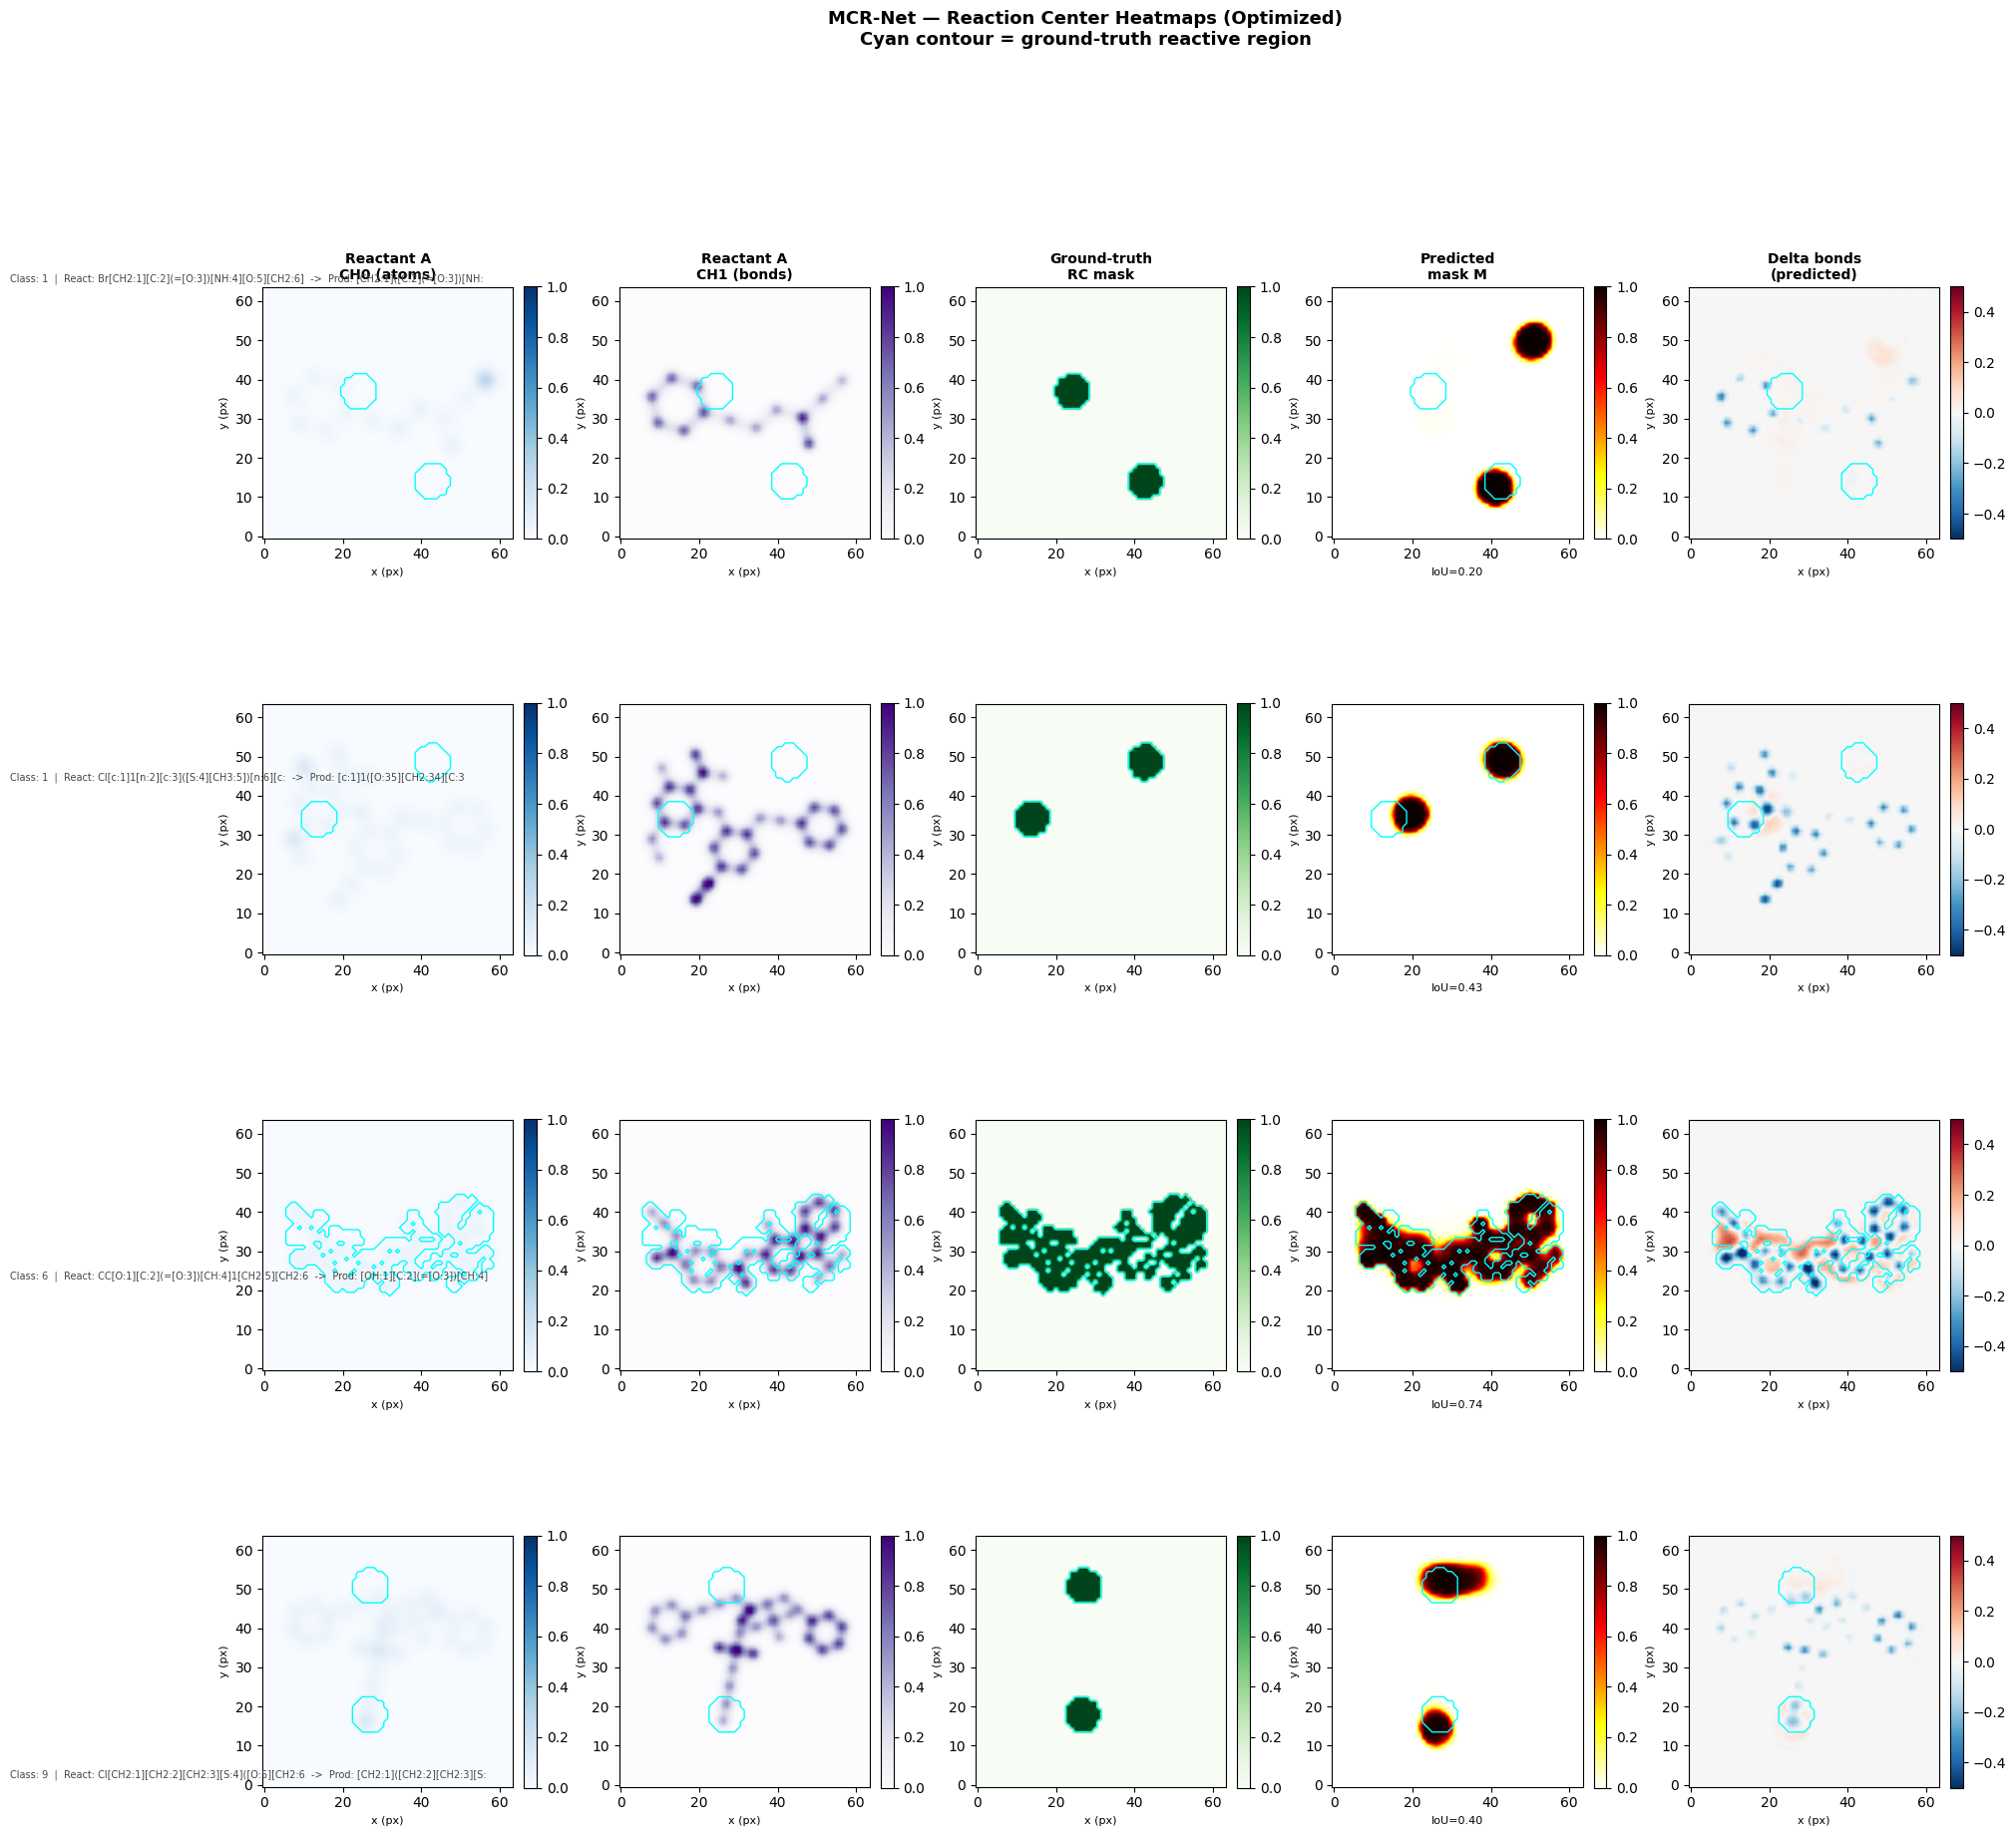

Saved: results/figures/heatmaps.png  ← Paper Figure 2


In [10]:
import os, torch, numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
THRESHOLD = 0.45
GRID, N_CH = 64, 7
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_raw_model.eval()
MODEL.eval()
N_ROWS = min(4, len(DS_VAL))
indices = np.random.choice(len(DS_VAL), N_ROWS, replace=False)

fig = plt.figure(figsize=(22, 5 * N_ROWS))
gs = gridspec.GridSpec(N_ROWS, 5, hspace=0.45, wspace=0.30)
col_titles = [
    "Reactant A\nCH0 (atoms)",
    "Reactant A\nCH1 (bonds)",
    "Ground-truth\nRC mask",
    "Predicted\nmask M",
    "Delta bonds\n(predicted)",
]
cmaps = ["Blues", "Purples", "Greens", "hot_r", "RdBu_r"]

with torch.no_grad():
    for row_i, idx in enumerate(indices):
        X, mt, Tpt, *_ = DS_VAL[idx]
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            mp, _, db, _, _ = _raw_model(X.unsqueeze(0).to(DEVICE))

        pm = mp.squeeze().cpu().numpy()
        db_n = db.squeeze().cpu().numpy()
        tm = mt.squeeze().numpy()
        X_np = X.numpy()

        panels = [X_np[0], X_np[1], tm, pm, db_n]
        vmins = [0, 0, 0, 0, -0.5]
        vmaxs = [1, 1, 1, 1, 0.5]

        for col_i, (data, cmap, vmin, vmax, title) in enumerate(zip(panels, cmaps, vmins, vmaxs, col_titles)):
            ax = fig.add_subplot(gs[row_i, col_i])
            im = ax.imshow(data, cmap=cmap, origin="lower", vmin=vmin, vmax=vmax, interpolation="bilinear")
            if row_i == 0:
                ax.set_title(title, fontsize=10, fontweight="bold")
            ax.set_xlabel("x (px)", fontsize=8)
            ax.set_ylabel("y (px)", fontsize=8)
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            if tm.max() > 0.1:
                ax.contour(tm, levels=[0.5], colors="cyan", linewidths=1.0)
            if col_i == 3:
                pb = (pm > THRESHOLD)
                tb = (tm > 0.5)
                iou = float((pb & tb).sum() / ((pb | tb).sum() + 1e-8))
                ax.set_xlabel(f"IoU={iou:.2f}", fontsize=8)

        s = DS_VAL.samples[idx]
        fig.text(
            0.01, 1 - (row_i + 0.5) / N_ROWS,
            f"Class: {s['reaction_class']}  |  React: {s['reactants'][:40]}  ->  Prod: {s['product'][:25]}",
            fontsize=7, va="center", color="#444", transform=fig.transFigure
        )

fig.suptitle(
    "MCR-Net — Reaction Center Heatmaps (Optimized)\n"
    "Cyan contour = ground-truth reactive region",
    fontsize=13, fontweight="bold", y=1.01
)
os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: results/figures/heatmaps.png  ← Paper Figure 2")

In [11]:
import os, json, torch, numpy as np
from collections import defaultdict
THRESHOLD = 0.45
GRID = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Build DS_TEST here — deferred from Section 3 ─────────────
# Keeps training RAM lower.
if DS_TEST is None:
    print("Building DS_TEST (deferred from Section 3)...")
    DS_TEST = MCRDataset(TEST_RECS, "Test")
    malloc_trim()
    DL_TEST = DataLoader(DS_TEST, **_loader_kwargs(train=False))
    print(f"Test: {len(DS_TEST)} samples  {len(DL_TEST)} batches")

def _to_py(obj):
    import numpy as _np
    if isinstance(obj, dict):
        return {k: _to_py(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [_to_py(v) for v in obj]
    if isinstance(obj, _np.integer):
        return int(obj)
    if isinstance(obj, (_np.floating, float)):
        return float(obj)
    if isinstance(obj, _np.ndarray):
        return obj.tolist()
    return obj

def _counts_from_batch(pm, tm, thr):
    pb = pm > thr
    tb = tm > 0.5
    tp = (pb & tb).sum().item()
    fp = (pb & (~tb)).sum().item()
    fn = ((~pb) & tb).sum().item()
    cr = ((pb & tb).view(pb.shape[0], -1).sum(1) > 0).sum().item()
    n = pm.shape[0]
    return tp, fp, fn, cr, n

def _metrics_from_counts(tp, fp, fn, cr, n):
    P = tp / (tp + fp + 1e-8)
    R = tp / (tp + fn + 1e-8)
    F1 = 2 * P * R / (P + R + 1e-8)
    IoU = tp / (tp + fp + fn + 1e-8)
    CR = cr / max(n, 1)
    return dict(precision=P, recall=R, f1=F1, iou=IoU, center_recall=CR)

def full_evaluation(model, dl, ds, split_name="Test", thr=None):
    model.eval()
    thresholds = np.arange(0.10, 0.90, 0.05) if thr is None else [float(thr)]

    # Pass 1: find the best threshold without storing every prediction
    search_stats = {float(t): [0, 0, 0, 0, 0] for t in thresholds}
    with torch.inference_mode():
        for X, mt, *_ in dl:
            X = X.to(DEVICE, non_blocking=True)
            mt = mt.to(DEVICE, non_blocking=True).float()
            if DEVICE.type == "cuda":
                X = X.contiguous(memory_format=torch.channels_last)
            with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
                mp, *_ = model(X)
            pm = mp.detach().float().cpu()
            tm = mt.detach().cpu()
            for t in thresholds:
                tp, fp, fn, cr, n = _counts_from_batch(pm, tm, t)
                acc = search_stats[float(t)]
                acc[0] += tp
                acc[1] += fp
                acc[2] += fn
                acc[3] += cr
                acc[4] += n

    if thr is None:
        best_thr, best_f1 = 0.45, -1.0
        for t, (tp, fp, fn, cr, n) in search_stats.items():
            m = _metrics_from_counts(tp, fp, fn, cr, n)
            if m["f1"] > best_f1:
                best_f1 = m["f1"]
                best_thr = t
        use_thr = best_thr
    else:
        use_thr = float(thr)

    # Pass 2: detailed overall + per-class metrics at chosen threshold
    overall = [0, 0, 0, 0, 0]
    cls_stats = defaultdict(lambda: [0, 0, 0, 0, 0])

    with torch.inference_mode():
        for X, mt, *_rest, rxn_cls in dl:
            X = X.to(DEVICE, non_blocking=True)
            mt = mt.to(DEVICE, non_blocking=True).float()
            if DEVICE.type == "cuda":
                X = X.contiguous(memory_format=torch.channels_last)
            with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
                mp, *_ = model(X)
            pm = mp.detach().float().cpu()
            tm = mt.detach().cpu()

            tp, fp, fn, cr, n = _counts_from_batch(pm, tm, use_thr)
            overall[0] += tp
            overall[1] += fp
            overall[2] += fn
            overall[3] += cr
            overall[4] += n

            pb = pm > use_thr
            tb = tm > 0.5
            for i, c in enumerate(rxn_cls):
                pbi = pb[i]
                tbi = tb[i]
                tp_i = (pbi & tbi).sum().item()
                fp_i = (pbi & (~tbi)).sum().item()
                fn_i = ((~pbi) & tbi).sum().item()
                cr_i = int((pbi & tbi).sum().item() > 0)
                cls_stats[str(c)][0] += tp_i
                cls_stats[str(c)][1] += fp_i
                cls_stats[str(c)][2] += fn_i
                cls_stats[str(c)][3] += cr_i
                cls_stats[str(c)][4] += 1

    fm = _metrics_from_counts(*overall)
    print("\n" + "=" * 62)
    print(f"  MCR-Net — {split_name}")
    print("=" * 62)
    print(f"  Samples    : {len(ds)}")
    print(f"  Threshold  : {use_thr:.2f}")
    print(f"  Precision  : {fm['precision']:.3f}")
    print(f"  Recall     : {fm['recall']:.3f}")
    print(f"  Pixel F1   : {fm['f1']:.3f}")
    print(f"  Pixel IoU  : {fm['iou']:.3f}")
    print(f"  Center Rec : {fm['center_recall']:.3f}")
    print("=" * 62)

    print(f"\n  Per-class (thr={use_thr:.2f})")
    print(f"  {'Class':<28} {'N':>5}  {'P':>6}  {'R':>6}  {'F1':>6}  {'IoU':>6}  {'CR':>6}")
    print("  " + "-" * 68)
    cr = []
    for cls in sorted(cls_stats.keys()):
        tp, fp, fn, ccr, n = cls_stats[cls]
        mc = _metrics_from_counts(tp, fp, fn, ccr, n)
        flag = " OK" if mc["f1"] > 0.70 else (" ??" if mc["f1"] > 0.50 else " !!")
        print(f"  {cls:<28} {n:>5}  {mc['precision']:>6.3f}  {mc['recall']:>6.3f}  "
              f"{mc['f1']:>6.3f}  {mc['iou']:>6.3f}  {mc['center_recall']:>6.3f}{flag}")
        cr.append({"class": cls, "n": n, **mc})

    mf1 = float(np.mean([r["f1"] for r in cr])) if cr else 0.0
    miou = float(np.mean([r["iou"] for r in cr])) if cr else 0.0
    print("  " + "-" * 68)
    print(f"  {'Macro average':<28} {'':>5}  {'':>6}  {'':>6}  {mf1:>6.3f}  {miou:>6.3f}")
    return _to_py(fm), _to_py(cr), float(use_thr)

print("Evaluating on validation set...")
val_m, val_cls, opt_thr = full_evaluation(_raw_model, DL_VAL, DS_VAL, "Validation")
print("\nEvaluating on test set...")
test_m, test_cls, _ = full_evaluation(_raw_model, DL_TEST, DS_TEST, "Test", thr=opt_thr)

print("\n" + "=" * 70)
print("  PAPER TABLE — MCR-Net vs Baselines")
print("=" * 70)
print(f"  {'Method':<30} {'F1':>6}  {'IoU':>6}  {'CR':>6}  {'Heatmap':>10}")
print("  " + "-" * 60)
print(f"  {'MCR-Net (ours)':<30} {test_m['f1']:>6.3f}  {test_m['iou']:>6.3f}  {test_m['center_recall']:>6.3f}  NATIVE")
print(f"  {'LocalTransform (2021)':<30} {'~0.85':>6}  {'N/A':>6}  {'~0.90':>6}  NO")
print(f"  {'Mol.Transformer (2019)':<30} {'N/A':>6}  {'N/A':>6}  {'N/A':>6}  NO")
print("=" * 70)

out = {
    "val_metrics": val_m,
    "test_metrics": test_m,
    "val_per_class": val_cls,
    "test_per_class": test_cls,
    "best_val_f1": float(ES.best) if "ES" in dir() and ES.best else None,
    "optimal_threshold": float(opt_thr),
    "n_train": len(DS_TRAIN),
    "n_val": len(DS_VAL),
    "n_test": len(DS_TEST),
    "epochs_trained": len(HIST["train_loss"]) if "HIST" in dir() else 0,
}
os.makedirs("results", exist_ok=True)
with open("results/results.json", "w") as f:
    json.dump(out, f, indent=2)
print("\nSaved: results/results.json")


Building DS_TEST (deferred from Section 3)...
  [Test] 5030 records


  Test:   0%|          | 0/5030 [00:00<?, ?it/s]

  Test: 5030 samples (0 skipped)
  RAM: ~0.8 GB (X float16 + T_prod uint8)
Test: 5030 samples  40 batches
Evaluating on validation set...

  MCR-Net — Validation
  Samples    : 5001
  Threshold  : 0.35
  Precision  : 0.673
  Recall     : 0.731
  Pixel F1   : 0.701
  Pixel IoU  : 0.540
  Center Rec : 0.978

  Per-class (thr=0.35)
  Class                            N       P       R      F1     IoU      CR
  --------------------------------------------------------------------
  1                             1515   0.653   0.687   0.670   0.503   0.983 ??
  10                              23   0.653   0.527   0.584   0.412   1.000 ??
  2                             1190   0.669   0.706   0.687   0.523   0.965 ??
  3                              566   0.654   0.647   0.650   0.482   0.982 ??
  4                               91   0.672   0.480   0.560   0.389   1.000 ??
  5                               67   0.671   0.653   0.662   0.495   0.970 ??
  6                              824   0.

In [12]:
import zipfile, glob, os
with zipfile.ZipFile('MCRNet_results.zip','w',zipfile.ZIP_DEFLATED) as zf:
    for fp in glob.glob('results/**/*',recursive=True):
        if os.path.isfile(fp): zf.write(fp)
print(f'Zip: {os.path.getsize("MCRNet_results.zip")/1e6:.1f} MB')
try:
    from google.colab import files
    files.download('MCRNet_results.zip')
except ImportError:
    print('Find MCRNet_results.zip in the working directory.')

Zip: 541.5 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>